In [4]:
## plot seasonal sapflow cycle (sapflow vs DOY)
# discard days with missing data
# don't include FATES DBH < 10 cm

In [4]:
import numpy as np
#
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
#
## this next library contains some helper functions for reshaping FATES variables into easier to work with dimensions
import ctsm_py.fates_xarray_funcs as fa       
#
import textwrap
from cmcrameri import cm
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader


In [5]:
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.autolayout'] = False
plt.rcParams['font.size'] = 14
##plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 300  # Set default DPI to 300 for poster figures


In [6]:
tag='hydro_comp_bmort_kmax_tune_sapflow_kmax3_5xHR_fixSLA_vcmax40.55_fixHR_branch'
path='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/SummaryFiles/'

In [9]:
file1=tag+'.elm.h2.cat.nc' # daily output
daily = xr.open_dataset(path+file1)


In [10]:
daily

<xarray.Dataset>
Dimensions:                        (levgrnd: 15, levlak: 10, levdcmp: 15,
                                    levsoi: 10, fates_levscls: 13,
                                    fates_levscag: 91, fates_levscpf: 26,
                                    fates_levcacls: 2, fates_levcapf: 4,
                                    fates_levage: 7, fates_levpft: 2,
                                    fates_levlanduse: 5, fates_levfuel: 6,
                                    ...
                                    fates_levelem: 1, fates_levelpft: 2,
                                    fates_levelcwd: 4, fates_levelage: 7,
                                    fates_levagefuel: 42, fates_levcdsc: 26,
                                    fates_levcdpf: 52, fates_levcdam: 2,
                                    time: 9126, hist_interval: 2, lon: 24,
                                    lat: 23)
Coordinates: (12/19)
  * levgrnd                        (levgrnd) float32 0.007101 0.02792 ... 35.18
  * levlak                         (levlak) float32 0.05 0.6 2.1 ... 34.33 44.78
  * levdcmp                        (levdcmp) float32 0.007101 0.02792 ... 35.18
  * levsoi                         (levsoi) float32 0.007101 0.02792 ... 2.865
  * fates_levscls                  (fates_levscls) float32 0.0 5.0 ... 100.0
  * fates_levcacls                 (fates_levcacls) float32 0.0 5.0
    ...                             ...
  * fates_levheight                (fates_levheight) float32 0.0 0.1 ... 10.0
  * fates_levelem                  (fates_levelem) int32 1
  * fates_levcdam                  (fates_levcdam) float32 0.0 80.0
  * time                           (time) object 0001-01-01 00:00:00 ... 0026...
  * lon                            (lon) float32 275.0 277.5 ... 330.0 332.5
  * lat                            (lat) float32 -25.58 -23.68 ... 14.21 16.11
Dimensions without coordinates: fates_levscag, fates_levscpf, fates_levcapf,
                                fates_levcnlf, fates_levcnlfpf,
                                fates_levscagpf, fates_levagepft,
                                fates_levelpft, fates_levelcwd, fates_levelage,
                                fates_levagefuel, fates_levcdsc, fates_levcdpf,
                                hist_interval
Data variables: (12/65)
    fates_scmap_levscag            (fates_levscag) int32 ...
    fates_agmap_levscag            (fates_levscag) int32 ...
    fates_pftmap_levscpf           (fates_levscpf) int32 ...
    fates_scmap_levscpf            (fates_levscpf) int32 ...
    fates_pftmap_levcapf           (fates_levcapf) int32 ...
    fates_camap_levcapf            (fates_levcapf) int32 ...
    ...                             ...
    FATES_TRAN_SZPF                (time, fates_levscpf, lat, lon) float32 ...
    FSH                            (time, lat, lon) float32 ...
    QSOIL                          (time, lat, lon) float32 ...
    QVEGE                          (time, lat, lon) float32 ...
    QVEGT                          (time, lat, lon) float32 ...
    RAIN                           (time, lat, lon) float32 ...
Attributes: (12/28)
    title:                                     ELM History file information
    source:                                    E3SM Land Model
    source_id:                                 2d74f509c8
    product:                                   model-output
    realm:                                     land
    case:                                      hydro_comp_bmort_kmax_tune_sap...
    ...                                        ...
    ltype_deep_lake:                           5
    ltype_wetland:                             6
    ltype_urban_tbd:                           7
    ltype_urban_hd:                            8
    ltype_urban_md:                            9
    NCO:                                       netCDF Operators version 5.2.4...

In [22]:
import cftime

def cftime_to_doy(cf_datetime_array):
  """
  Converts an array (or list) of cftime.DatetimeNoLeap() objects to an array of DOY values.

  Args:
    cf_datetime_array: An iterable (e.g., list, array) of cftime.DatetimeNoLeap() objects.

  Returns:
    A list of integers representing the day of year (1-365) for each input datetime object.
    Returns an empty list if the input is empty or contains non-cftime.DatetimeNoLeap objects.
  """
  doy_array = []
  for cf_datetime in cf_datetime_array:
    if isinstance(cf_datetime, cftime.DatetimeNoLeap):
      doy_array.append(cf_datetime.dayofyr)
    else:
      print(f"Warning: Skipping non-cftime.DatetimeNoLeap object: {cf_datetime}")
  return doy_array


In [23]:
fates_doy=cftime_to_doy(daily.time.values)

In [24]:
# how many years did I average over
nyears = 25

# spatial size
nlat=23
nlon=24

In [25]:
# conversion factors
cm2_per_m2 = 10000.0
g_per_kg = 1000.0

In [26]:
sapflow_raw=fa.scpf_to_scls_by_pft(daily.FATES_SAPFLOW_SZPF,daily)
sapwood_area=fa.scpf_to_scls_by_pft(daily.FATES_SAPWOOD_AREA_SZPF,daily)


In [27]:
bionte_lat, bionte_lon = -2.6, 360.0 - 60.2  # = 299.8
lat_idx = np.argmin(np.abs(d1.lat.values - bionte_lat))
lon_idx = np.argmin(np.abs(d1.lon.values - bionte_lon))
lat_slice = slice(lat_idx - 1, lat_idx + 2)
lon_slice = slice(lon_idx - 1, lon_idx + 2)

In [28]:
sapflow=sapflow_raw.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))/sapwood_area.isel(lat=lat_slice, lon=lon_slice).mean(dim=('lat', 'lon'))


In [35]:
fates_days=np.unique(fates_doy)

In [82]:
daily_early_mean = sapflow.groupby('time.dayofyear').mean(dim='time').isel(fates_levpft=0).isel(fates_levscls=slice(2,14)).mean(dim='fates_levscls')

In [83]:
daily_late_mean = sapflow.groupby('time.dayofyear').mean(dim='time').isel(fates_levpft=1).isel(fates_levscls=slice(2,14)).mean(dim='fates_levscls')

In [87]:
daily_early_std = sapflow.groupby('time.dayofyear').std(dim='time').isel(fates_levpft=0).isel(fates_levscls=slice(2,14)).std(dim='fates_levscls')

/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedo

In [88]:
daily_late_std = sapflow.groupby('time.dayofyear').std(dim='time').isel(fates_levpft=1).isel(fates_levscls=slice(2,14)).std(dim='fates_levscls')

/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/j/jkowalcz/.conda/envs/myenv/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedo

In [44]:
import pandas as pd
## read in BIONTE sapflow data
# From Yilin (1/24/25): units are g/cm2/h.
bionte_sapflow_csv='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FromYilin/Js_All_2022_2023.csv'

# Load the data
bionte_sapflow_data = pd.read_csv(bionte_sapflow_csv)


In [45]:
# read in wood density, DBH etc

bionte_info_csv='/pscratch/sd/j/jkowalcz/e3sm_scratch/pm-cpu/Benchmarks/BIONTE_sapflow/FromYilin/Abstract_Bionte.csv'
bionte_info = pd.read_csv(bionte_info_csv)


In [46]:
bionte_wd=bionte_info['WD'].values
bionte_dbh=bionte_info['DBH'].values

In [47]:
def create_string_list(int_array):
    """
    Takes an array of integers and returns a list of strings with 's' plus the 
    value of the integer plus 1.

    Args:
        int_array (list or numpy.ndarray): An array of integers.

    Returns:
        list: A list of strings.
    """
    string_list = []
    for num in int_array:
#        print(num)
        string_list.append(f's{num + 1}')  # Using f-strings for string formatting
    return string_list

In [48]:
bionte_dbh_ind = np.where((bionte_dbh > 0) & (bionte_dbh < 10000))

In [49]:
sensors=create_string_list(bionte_dbh_ind[0])

In [59]:
# 1. Group by unique calendar day
grouped = bionte_sapflow_data.groupby(['year', 'doy'])

# 2. Count non-null readings and compute daily means per sensor
valid_counts = grouped[sensors].count()
daily_means = grouped[sensors].mean()

# 3. Create a boolean mask of valid sensor-day combinations 
valid_mask = valid_counts == 48

# 4. Mask out invalid daily means (sets them to NaN for that specific sensor on that day)
daily_means_filtered = daily_means.where(valid_mask)

# Calculates DOY mean ignoring NaNs from incomplete sensor-days
obs_sapflow = daily_means_filtered.groupby('doy').mean()

In [60]:
obs_sapflow_mean_all = obs_sapflow.mean(axis=1, skipna=True)

In [61]:
obs_sapflow_std_all= obs_sapflow.std(axis=1, skipna=True)

In [62]:
obs_sapflow_mean_all

doy
1      1.489929
2      1.124880
3      1.649817
4      2.780254
5      2.636682
         ...   
361    0.976107
362    1.971239
363    1.777976
364    2.207334
365    1.163530
Length: 365, dtype: float64

In [63]:
sapflow_ymin=0
sapflow_ymax=7

In [64]:
# convert from kg/m^2/s to g/cm^2/hr

cf=1000*3600/(100**2)

# density of water is 1 g/cm^3
# g/cm^2/hr * (1/density of water) = sap velocity in cm/hr


In [93]:
# BIONTE dry season is June - October (Negron-Juarez et al 2017)
from matplotlib.patches import Rectangle
color='burlywood'
dpm=np.max(fates_doy)/12.

# BIONTE dry season is June - October (Negron-Juarez et al 2017)
gswp_bionte_dry=Rectangle((5*dpm,sapflow_ymin),5*dpm,sapflow_ymax-sapflow_ymin, hatch='xx',edgecolor='lightgrey',facecolor="white")

# or define dry season by where rain < 100 mm/month
#gswp_bionte_dry=Rectangle((5*dpm,sapflow_ymin),5*dpm,sapflow_ymax-sapflow_ymin, facecolor=color, alpha=0.5)


Text(0.5, 1.0, 'BIONTE sapflow, all trees > 10 cm')

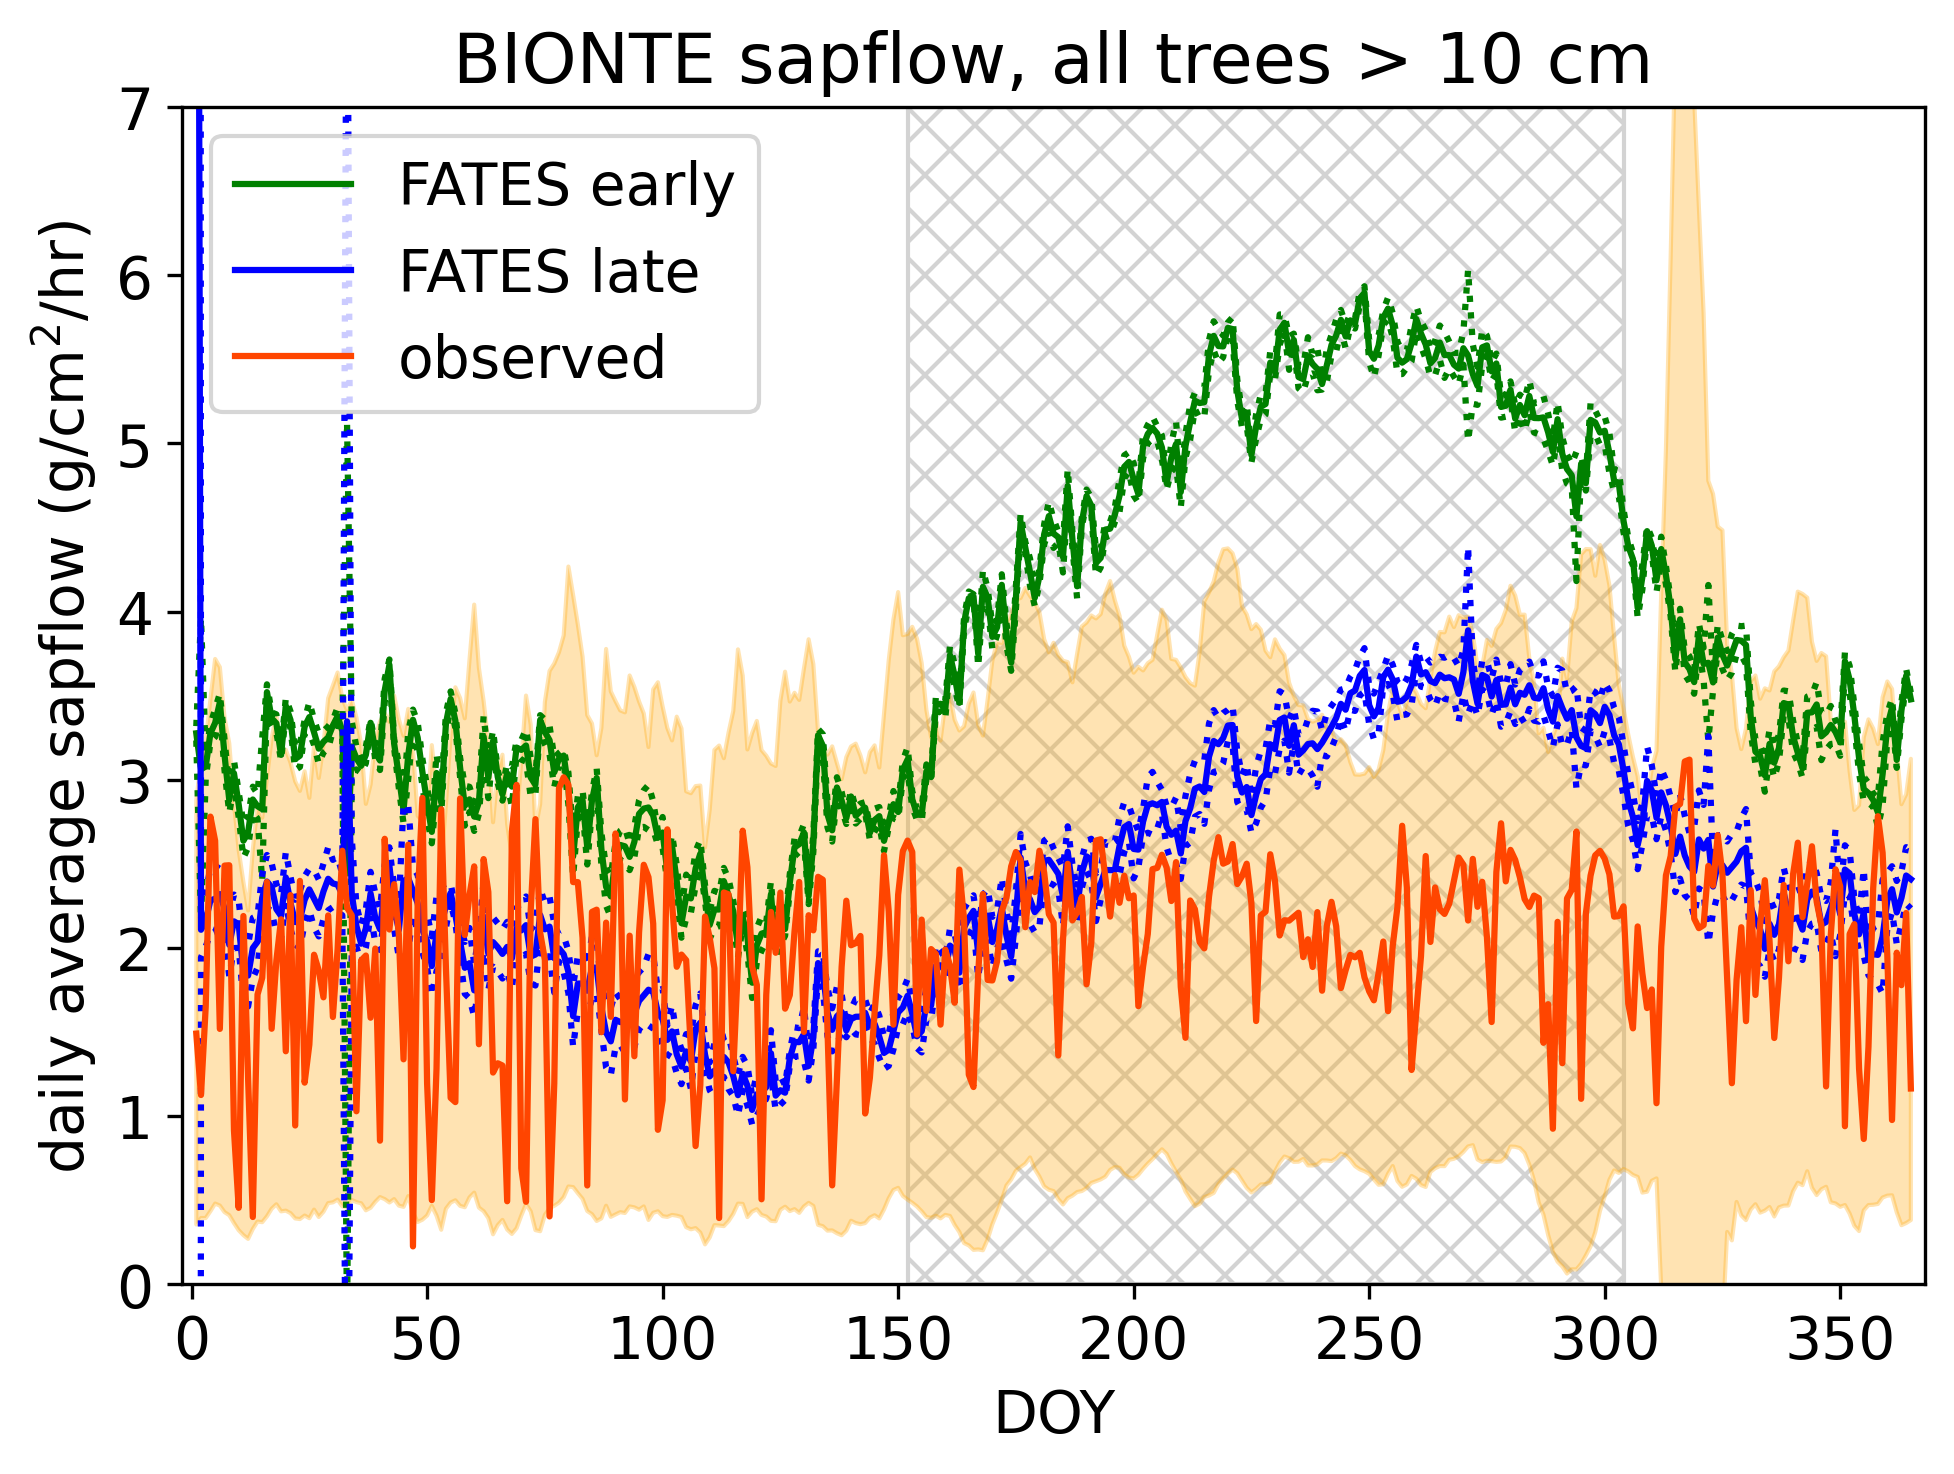

In [94]:
## add light brown bar showing dry season
# fig.text(0.22,0.9,'green = early PFT, blue = late PFT, orange = observed',fontsize=20)
from scipy.ndimage import uniform_filter1d

plt.gca().add_patch(gswp_bionte_dry)
plt.plot(fates_days, cf*daily_early_mean, color="green",label='FATES early')
plt.plot(fates_days,cf*daily_early_mean-cf*daily_early_std, color="green",linestyle="dotted")
plt.plot(fates_days,cf*daily_early_mean+cf*daily_early_std, color="green",linestyle="dotted")
plt.plot(fates_days, cf*daily_late_mean, color="blue",label='FATES late')
plt.plot(fates_days, cf*daily_late_mean-cf*daily_late_std, color="blue",linestyle="dotted")
plt.plot(fates_days, cf*daily_late_mean+cf*daily_late_std, color="blue",linestyle="dotted")

plt.plot(fates_days, obs_sapflow_mean_all, color="orangered",label='observed')
plt.fill_between(fates_days, uniform_filter1d(obs_sapflow_mean_all-obs_sapflow_std_all,size=7), uniform_filter1d(obs_sapflow_mean_all+obs_sapflow_std_all,size=7), color='orange', alpha=0.3)

plt.ylabel('daily average sapflow (g/cm$^2$/hr)')
plt.xlabel('DOY')
plt.xlim(-2,368)
plt.ylim(sapflow_ymin,sapflow_ymax)
plt.legend()
plt.title('BIONTE sapflow, all trees > 10 cm')